## Giai đoạn 1. Thu thập và đánh giá dữ liệu ban đầu

In [1]:
# Cài kagglehub và nạp thư viện
!pip install -q kagglehub statsmodels

import os, warnings
from glob import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import platform, scipy, matplotlib
import statsmodels
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.proportion import proportion_confint
from statsmodels.stats.multitest import multipletests

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

# Seed cố định cho toàn bộ bootstrap
SEED = 42
np.random.seed(SEED)

# In phiên bản để ghi vào mục phương pháp và tính tái lập của báo cáo
for name, ver in [("Python", platform.python_version()), ("NumPy", np.__version__),
                  ("Pandas", pd.__version__), ("SciPy", scipy.__version__),
                  ("Matplotlib", matplotlib.__version__), ("Seaborn", sns.__version__),
                  ("Statsmodels", statsmodels.__version__)]:
    print(f"{name}: {ver}")

# Hình được lưu vào thư mục này để chèn vào báo cáo. Colab xóa nó khi session reset nên nhớ tải về.
FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

def show(name):
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/{name}.png", dpi=300, bbox_inches="tight")
    plt.show()

def fmt_p(p):
    # Mẫu lớn nên p rất nhỏ, quy ước báo cáo là "< 0.001" thay vì in số mũ
    return "< 0.001" if p < 0.001 else f"= {p:.3f}"


Python: 3.13.18
NumPy: 2.4.6
Pandas: 2.2.3
SciPy: 1.16.3
Matplotlib: 3.10.0
Seaborn: 0.13.2
Statsmodels: 0.15.0


In [2]:
# Tải dữ liệu từ Kaggle, nếu không được thì đọc adult.csv trong /content
def load_adult():
    try:
        import kagglehub
        folder = kagglehub.dataset_download("uciml/adult-census-income")
        # Tìm theo đuôi .csv để không phụ thuộc vào tên file
        csv_path = sorted(glob(os.path.join(folder, "**", "*.csv"), recursive=True))[0]
        print("Đã tải từ Kaggle:", csv_path)
    except Exception as e:
        print("Không tải được từ Kaggle (" + type(e).__name__ + "), thử file local")
        found = glob("/content/adult.csv") + glob("adult.csv")
        if not found:
            raise FileNotFoundError("Hãy upload adult.csv vào /content rồi chạy lại cell này")
        csv_path = found[0]
    return pd.read_csv(csv_path)

df_raw = load_adult()
# Dừng ngay nếu nạp nhầm file hoặc phiên bản khác
assert df_raw.shape == (32561, 15), f"Kích thước bất thường: {df_raw.shape}"

# Tên cột gốc có dấu chấm nên df.education.num sẽ bị hiểu là thuộc tính, đổi sang gạch dưới
df_raw.columns = df_raw.columns.str.replace(".", "_", regex=False)

df = df_raw.copy()

Using Colab cache for faster access to the 'adult-census-income' dataset.
Đã tải từ Kaggle: /kaggle/input/adult-census-income/adult.csv


In [3]:
# Cấu trúc và kiểu dữ liệu
print("Kích thước:", df.shape)
df.info()
display(df.head())

num_cols = df.select_dtypes(include="number").columns.tolist()
# Pandas 3 cảnh báo select_dtypes("object") sẽ không còn chọn cột chuỗi, nên loại trừ cột số
cat_cols = df.select_dtypes(exclude="number").columns.tolist()
print("Cột số:", num_cols)
print("Cột chữ:", cat_cols)

display(df[num_cols].describe().T)

Kích thước: (32561, 15)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       32561 non-null  object
 2   fnlwgt          32561 non-null  int64 
 3   education       32561 non-null  object
 4   education_num   32561 non-null  int64 
 5   marital_status  32561 non-null  object
 6   occupation      32561 non-null  object
 7   relationship    32561 non-null  object
 8   race            32561 non-null  object
 9   sex             32561 non-null  object
 10  capital_gain    32561 non-null  int64 
 11  capital_loss    32561 non-null  int64 
 12  hours_per_week  32561 non-null  int64 
 13  native_country  32561 non-null  object
 14  income          32561 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.7+ MB


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,90,?,77053,HS-grad,9,Widowed,?,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66,?,186061,Some-college,10,Widowed,?,Unmarried,Black,Female,0,4356,40,United-States,<=50K
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K


Cột số: ['age', 'fnlwgt', 'education_num', 'capital_gain', 'capital_loss', 'hours_per_week']
Cột chữ: ['workclass', 'education', 'marital_status', 'occupation', 'relationship', 'race', 'sex', 'native_country', 'income']


,count,mean,std,min,25%,50%,75%,max
age,32561.0,38.581647,13.640433,17.0,28.0,37.0,48.0,90.0
fnlwgt,32561.0,189778.366512,105549.977697,12285.0,117827.0,178356.0,237051.0,1484705.0
education_num,32561.0,10.080679,2.572720,1.0,9.0,10.0,12.0,16.0
capital_gain,32561.0,1077.648844,7385.292085,0.0,0.0,0.0,0.0,99999.0
capital_loss,32561.0,87.303830,402.960219,0.0,0.0,0.0,0.0,4356.0
hours_per_week,32561.0,40.437456,12.347429,1.0,40.0,40.0,45.0,99.0


In [4]:
# Missing value, dữ liệu này mã hóa thiếu bằng "?"
# isna() chỉ thấy NaN thật nên phải đếm "?" riêng
print("Số ô NaN thật:", int(df.isna().sum().sum()))

q_count = df[cat_cols].apply(lambda s: s.str.strip().eq("?").sum())
q_tbl = pd.DataFrame({"so_dong": q_count, "ty_le_%": (q_count / len(df) * 100).round(2)})
display(q_tbl[q_tbl["so_dong"] > 0])

Số ô NaN thật: 0


,so_dong,ty_le_%
workclass,1836,5.64
occupation,1843,5.66
native_country,583,1.79


In [5]:
# Phân phối target và tính nhất quán giữa education với education_num
print(df["income"].str.strip().value_counts())
print(df["income"].str.strip().value_counts(normalize=True).round(4))

# Cả hai chiều đều bằng 1 nghĩa là hai cột mã hóa cùng một thông tin
print("Số mã education_num tối đa ứng với 1 education:",
      df.groupby("education")["education_num"].nunique().max())
print("Số education tối đa ứng với 1 mã education_num:",
      df.groupby("education_num")["education"].nunique().max())

# Số giá trị phân biệt của từng cột, đối chiếu với Bảng 1.2. income phải có đúng 2 nhãn
print(df_raw.nunique())
assert df["income"].str.strip().nunique() == 2


income
<=50K    24720
>50K      7841
Name: count, dtype: int64
income
<=50K    0.7592
>50K     0.2408
Name: proportion, dtype: float64
Số mã education_num tối đa ứng với 1 education: 1
Số education tối đa ứng với 1 mã education_num: 1
age                  73
workclass             9
fnlwgt            21648
education            16
education_num        16
marital_status        7
occupation           15
relationship          6
race                  5
sex                   2
capital_gain        119
capital_loss         92
hours_per_week       94
native_country       42
income                2
dtype: int64


## Giai đoạn 2. Tiền xử lý và làm sạch dữ liệu

### 2.1 Giá trị thiếu

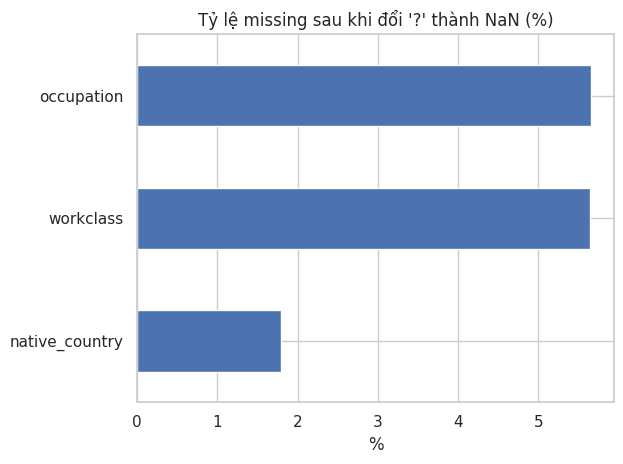

native_country    1.79
workclass         5.64
occupation        5.66
dtype: float64


In [6]:
# Đổi "?" thành NaN và tạo target nhị phân
for c in cat_cols:
    df[c] = df[c].str.strip().replace("?", np.nan)

df["income_bin"] = (df["income"] == ">50K").astype(int)

miss_pct = df.isna().mean().mul(100)
miss_pct = miss_pct[miss_pct > 0].sort_values()
miss_pct.plot.barh(title="Tỷ lệ missing sau khi đổi '?' thành NaN (%)")
plt.xlabel("%")
show("01_missing")
print(miss_pct.round(2))

In [7]:
# Kiểm tra cơ chế thiếu
# workclass và occupation thiếu gần như cùng các dòng
print(pd.crosstab(df["workclass"].isna(), df["occupation"].isna(),
                  rownames=["workclass thiếu"], colnames=["occupation thiếu"]))

# Các dòng chỉ thiếu occupation
print(df.loc[df["occupation"].isna() & df["workclass"].notna(), "workclass"].value_counts())

# Xét từng cột riêng. Gộp thành một cờ "có thiếu" sẽ che mất việc native_country
# hành xử khác hai cột còn lại.
rows = []
for c in ["workclass", "occupation", "native_country"]:
    m = df[c].isna()
    rows.append({"cot": c, "n_thieu": int(m.sum()),
                 "ty_le_>50K_khi_thieu_%": round(df.loc[m, "income_bin"].mean() * 100, 1),
                 "ty_le_>50K_khi_du_%": round(df.loc[~m, "income_bin"].mean() * 100, 1)})
display(pd.DataFrame(rows))

# Trạng thái thiếu có liên hệ với đặc điểm quan sát được không. Nếu có thì không phải MCAR,
# nhưng các p-value này không đủ để phân biệt MAR với MNAR.
def p_str(p):
    return "< 0.001" if p < 0.001 else f"{p:.3f}"

miss_rows = []
for c in ["workclass", "occupation", "native_country"]:
    m = df[c].isna()
    miss_rows.append({
        "cot": c,
        "p_income (chi2)": p_str(stats.chi2_contingency(pd.crosstab(m, df["income_bin"]))[1]),
        "p_sex (chi2)": p_str(stats.chi2_contingency(pd.crosstab(m, df["sex"]))[1]),
        "p_age (MWU)": p_str(stats.mannwhitneyu(df.loc[m, "age"], df.loc[~m, "age"])[1]),
        "p_education_num (MWU)": p_str(stats.mannwhitneyu(df.loc[m, "education_num"], df.loc[~m, "education_num"])[1]),
    })
display(pd.DataFrame(miss_rows))


occupation thiếu  False  True 
workclass thiếu               
False             30718      7
True                  0   1836
workclass
Never-worked    7
Name: count, dtype: int64


,cot,n_thieu,ty_le_>50K_khi_thieu_%,ty_le_>50K_khi_du_%
0,workclass,1836,10.4,24.9
1,occupation,1843,10.4,24.9
2,native_country,583,25.0,24.1


,cot,p_income (chi2),p_sex (chi2),p_age (MWU),p_education_num (MWU)
0,workclass,< 0.001,< 0.001,0.722,< 0.001
1,occupation,< 0.001,< 0.001,0.550,< 0.001
2,native_country,0.618,0.009,0.457,< 0.001


In [8]:
# Điền missing bằng nhãn "Unknown"
# Cả ba cột đều là biến phân loại. Với workclass và occupation, thiếu đi cùng tỷ lệ thu nhập
# khác hẳn, nên điền mode sẽ gán nghề phổ biến cho người không khai báo. Nhãn riêng giữ được
# số dòng và cả thông tin "không khai báo". native_country làm cùng cách cho nhất quán.
for c in ["workclass", "occupation", "native_country"]:
    df[c] = df[c].fillna("Unknown")

assert df.isna().sum().sum() == 0
print("Còn missing:", int(df.isna().sum().sum()))

Còn missing: 0


### 2.2 Dòng trùng lặp

In [9]:
# Tìm dòng trùng lặp
n_dup = df.duplicated().sum()
print("Số dòng bị đánh dấu trùng (giữ bản đầu):", n_dup)
print("Tổng số dòng thuộc các nhóm trùng:", df.duplicated(keep=False).sum())
display(df[df.duplicated(keep=False)].sort_values(["age", "fnlwgt"]).head(6))

# Các bản trùng có nhãn income mâu thuẫn nhau không
feat_cols = [c for c in df.columns if c not in ("income", "income_bin")]
grp = df[df.duplicated(keep=False)].groupby(feat_cols, dropna=False)["income"].nunique()
print("Số nhóm trùng có nhãn income khác nhau:", int((grp > 1).sum()))

Số dòng bị đánh dấu trùng (giữ bản đầu): 24
Tổng số dòng thuộc các nhóm trùng: 47


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income,income_bin
19622,19,Private,97261,HS-grad,9,Never-married,Farming-fishing,Not-in-family,White,Male,0,0,40,United-States,<=50K,0
20507,19,Private,97261,HS-grad,9,Never-married,Farming-fishing,Not-in-family,White,Male,0,0,40,United-States,<=50K,0
10307,19,Private,138153,Some-college,10,Never-married,Adm-clerical,Own-child,White,Female,0,0,10,United-States,<=50K,0
22783,19,Private,138153,Some-college,10,Never-married,Adm-clerical,Own-child,White,Female,0,0,10,United-States,<=50K,0
17456,19,Private,146679,Some-college,10,Never-married,Exec-managerial,Own-child,Black,Male,0,0,30,United-States,<=50K,0
22934,19,Private,146679,Some-college,10,Never-married,Exec-managerial,Own-child,Black,Male,0,0,30,United-States,<=50K,0


Số nhóm trùng có nhãn income khác nhau: 0


In [10]:
# Loại dòng trùng
# Không có cột ID nên không chứng minh chắc chắn đây là bản ghi lặp. Loại vì chỉ 24 dòng
# và nhãn nhất quán, rồi so tỷ lệ >50K trước sau để xem ảnh hưởng.
rate_before = df["income_bin"].mean() * 100
n_before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"{n_before} -> {len(df)} dòng | tỷ lệ >50K: {rate_before:.3f}% -> {df['income_bin'].mean()*100:.3f}%")

32561 -> 32537 dòng | tỷ lệ >50K: 24.081% -> 24.093%


### 2.3 Ngoại lệ

In [11]:
# Phát hiện outlier bằng IQR
def iqr_report(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - k * iqr, q3 + k * iqr
    n = ((s < lo) | (s > hi)).sum()
    return pd.Series({"Q1": q1, "Q3": q3, "can_duoi": lo, "can_tren": hi,
                      "so_outlier": n, "ty_le_%": round(n / len(s) * 100, 2),
                      "min": s.min(), "max": s.max()})

# fnlwgt chỉ xét ở đây để báo cáo, các bước sau không dùng vì nó là trọng số lấy mẫu
num_cols = ["age", "fnlwgt", "education_num", "capital_gain", "capital_loss", "hours_per_week"]
display(df[num_cols].apply(iqr_report).T)

,Q1,Q3,can_duoi,can_tren,so_outlier,ty_le_%,min,max
age,28.0,48.0,-2.0,78.0,142.0,0.44,17.0,90.0
fnlwgt,117827.0,236993.0,-60922.0,415742.0,993.0,3.05,12285.0,1484705.0
education_num,9.0,12.0,4.5,16.5,1193.0,3.67,1.0,16.0
capital_gain,0.0,0.0,0.0,0.0,2712.0,8.34,0.0,99999.0
capital_loss,0.0,0.0,0.0,0.0,1519.0,4.67,0.0,4356.0
hours_per_week,40.0,45.0,32.5,52.5,9002.0,27.67,1.0,99.0


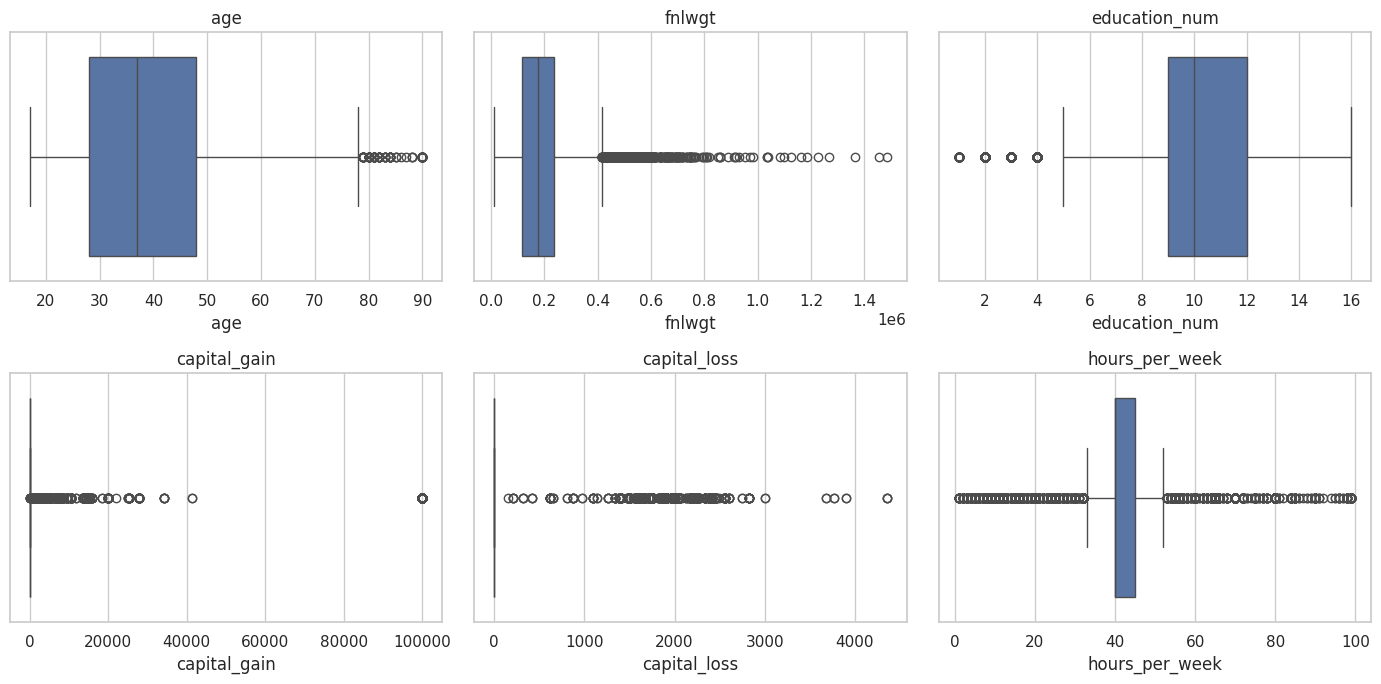

In [12]:
# Boxplot các cột số
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, c in zip(axes.ravel(), num_cols):
    sns.boxplot(x=df[c], ax=ax)
    ax.set_title(c)
show("02_boxplot_numeric")

In [13]:
# capital_gain và capital_loss
# Hơn 90% giá trị là 0 nên Q1 = Q3 = 0 và IQR = 0, mọi giá trị khác 0 đều bị gắn outlier.
# Kết quả IQR ở hai cột này không có ý nghĩa, nên mô tả bằng tỷ lệ khác 0 và đuôi phân phối.
for c in ["capital_gain", "capital_loss"]:
    nz = df[c] > 0
    print(f"{c}: khác 0 = {nz.mean()*100:.2f}% (n = {nz.sum()}) | median(khác 0) = {df.loc[nz, c].median():,.0f}"
          f" | max = {df[c].max():,}")

# 99999 lặp lại nhiều bất thường, giống giá trị bị chặn trên hơn là số đo thật
print("\nSố dòng capital_gain = 99999:", (df["capital_gain"] == 99999).sum())
print("Nhãn income của nhóm này:", df.loc[df["capital_gain"] == 99999, "income"].value_counts().to_dict())
print("\nCác giá trị capital_gain xuất hiện nhiều nhất:")
print(df["capital_gain"].value_counts().head(5))
print("\nDòng có đồng thời gain > 0 và loss > 0:", ((df["capital_gain"] > 0) & (df["capital_loss"] > 0)).sum())

capital_gain: khác 0 = 8.34% (n = 2712) | median(khác 0) = 7,298 | max = 99,999
capital_loss: khác 0 = 4.67% (n = 1519) | median(khác 0) = 1,887 | max = 4,356

Số dòng capital_gain = 99999: 159
Nhãn income của nhóm này: {'>50K': 159}

Các giá trị capital_gain xuất hiện nhiều nhất:
capital_gain
0        29825
15024      347
7688       284
7298       246
99999      159
Name: count, dtype: int64

Dòng có đồng thời gain > 0 và loss > 0: 0


In [14]:
# Độ nhạy với capital_gain = 99999. Chỉ loại tạm trong phép tính này, df chính không đổi.
sens = {"Toàn bộ dữ liệu": df, "Loại capital_gain = 99999": df[df["capital_gain"] != 99999]}
sens_rows = []
for name, d in sens.items():
    rho_s, p_s = stats.spearmanr(d["capital_gain"], d["income_bin"])
    sens_rows.append({"truong_hop": name, "n": len(d), "spearman_rho": round(rho_s, 3),
                      "ty_le_>50K_%": round(d["income_bin"].mean() * 100, 2)})
display(pd.DataFrame(sens_rows))

,truong_hop,n,spearman_rho,ty_le_>50K_%
0,Toàn bộ dữ liệu,32537,0.278,24.09
1,Loại capital_gain = 99999,32378,0.257,23.72


In [15]:
# hours_per_week và age
# Gần một nửa số dòng nằm đúng ở 40 giờ nên khoảng Q1 đến Q3 chỉ rộng 5 giờ, IQR vì vậy
# gắn outlier cho rất nhiều dòng dù các giá trị này không phải lỗi.
print("Tỷ lệ hours = 40: %.1f%%" % ((df["hours_per_week"] == 40).mean() * 100))
print("hours >= 80:", (df["hours_per_week"] >= 80).sum(), "| hours == 99:", (df["hours_per_week"] == 99).sum())
print("age >= 80:", (df["age"] >= 80).sum(), "| age == 90:", (df["age"] == 90).sum(), "| tuổi nhỏ nhất:", df["age"].min())

# Nhóm cực trị có hành xử khác phần còn lại không, để quyết định giữ hay bỏ
print("\nTỷ lệ >50K: toàn mẫu %.1f%% | hours >= 80: %.1f%% | age >= 80: %.1f%%" % (
    df["income_bin"].mean() * 100,
    df.loc[df["hours_per_week"] >= 80, "income_bin"].mean() * 100,
    df.loc[df["age"] >= 80, "income_bin"].mean() * 100))

Tỷ lệ hours = 40: 46.7%
hours >= 80: 341 | hours == 99: 85
age >= 80: 120 | age == 90: 42 | tuổi nhỏ nhất: 17

Tỷ lệ >50K: toàn mẫu 24.1% | hours >= 80: 35.2% | age >= 80: 13.3%


### 2.4 Biến đổi và mã hóa

In [16]:
# Tạo biến nhóm và biến đổi log
# Tuổi nhỏ nhất là 17 nên khoảng đầu bắt đầu từ 16
df["age_group"] = pd.cut(df["age"], bins=[16, 24, 34, 44, 54, 64, 100],
                         labels=["17-24", "25-34", "35-44", "45-54", "55-64", "65+"])
# Mốc 40 giờ được tách riêng vì là giá trị phổ biến nhất
df["hours_group"] = pd.cut(df["hours_per_week"], bins=[0, 34, 40, 50, 100],
                           labels=["<=34", "35-40", "41-50", ">50"])

# log1p thay vì log vì hai cột có rất nhiều giá trị 0
df["log_cap_gain"] = np.log1p(df["capital_gain"])
df["log_cap_loss"] = np.log1p(df["capital_loss"])

# Mỹ chiếm khoảng 90% còn các nước khác mỗi nước rất ít dòng, gộp lại để bảng và biểu đồ không loãng
df["native_group"] = np.select(
    [df["native_country"] == "United-States", df["native_country"] == "Unknown"],
    ["US", "Unknown"], default="Non-US")
print(df["native_group"].value_counts())

# Biến phục vụ mô hình logistic. Cờ nhị phân phù hợp hơn log1p vì phần lớn giá trị bằng 0
df["has_cap_gain"] = (df["capital_gain"] > 0).astype(int)
df["has_cap_loss"] = (df["capital_loss"] > 0).astype(int)
# Center hóa tuổi để giảm tương quan giữa age và age^2 trong hồi quy bậc hai
df["age_c"] = df["age"] - df["age"].mean()
df["age_c2"] = df["age_c"] ** 2


native_group
US         29153
Non-US      2802
Unknown      582
Name: count, dtype: int64


,skew_goc,skew_log1p
capital_gain,11.95,3.09
capital_loss,4.59,4.31


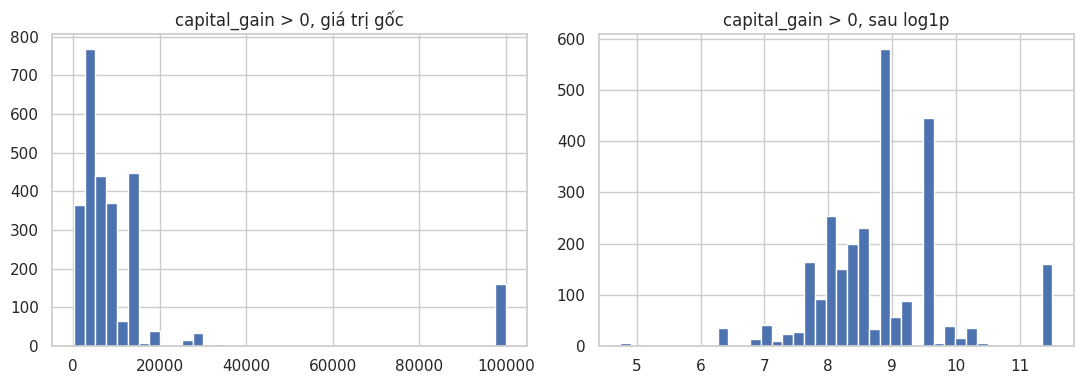

Độ lệch của nhóm > 0: gốc 3.41 -> log1p 0.56


In [17]:
# Độ lệch trước và sau log1p
skew_tbl = pd.DataFrame({
    "skew_goc": [df["capital_gain"].skew(), df["capital_loss"].skew()],
    "skew_log1p": [df["log_cap_gain"].skew(), df["log_cap_loss"].skew()],
}, index=["capital_gain", "capital_loss"]).round(2)
display(skew_tbl)

# Vẽ riêng các dòng khác 0, vì phần giá trị 0 chiếm đa số sẽ che hết phần còn lại
pos = df[df["capital_gain"] > 0]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(pos["capital_gain"], bins=40)
axes[0].set_title("capital_gain > 0, giá trị gốc")
axes[1].hist(pos["log_cap_gain"], bins=40)
axes[1].set_title("capital_gain > 0, sau log1p")
show("03_capital_gain_log")
print("Độ lệch của nhóm > 0: gốc %.2f -> log1p %.2f" % (pos["capital_gain"].skew(), pos["log_cap_gain"].skew()))

## Giai đoạn 3. Phân tích và trực quan hóa

In [18]:
# Hàm dùng chung cho phần kiểm định
def cramers_v(x, y):
    # V nằm trong [0, 1], dùng để so độ mạnh liên hệ giữa các biến phân loại
    ct = pd.crosstab(x, y)
    chi2, p, _, _ = stats.chi2_contingency(ct)
    v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
    return chi2, p, v

def rate_by(col):
    # Luôn kèm n vì nhóm nhỏ cho tỷ lệ không ổn định
    g = df.groupby(col, observed=True)["income_bin"]
    return pd.DataFrame({"ty_le_%": g.mean().mul(100).round(1), "n": g.size()})

print("Tỷ lệ >50K toàn mẫu: %.2f%%" % (df["income_bin"].mean() * 100))

Tỷ lệ >50K toàn mẫu: 24.09%


In [19]:
# Hàm thống kê bổ sung: Wilson CI, Cramér's V hiệu chỉnh, bootstrap CI, Cohen's h, CLES
BASE = df["income_bin"].mean() * 100   # mức nền toàn mẫu (%)
p_hyp = {}                              # p-value riêng của từng giả thuyết, dùng cho Holm

def rate_ci(col, min_n=30):
    # Tỷ lệ >50K theo nhóm kèm CI Wilson 95%. Nhóm n < min_n bị đánh dấu kém ổn định
    g = df.groupby(col, observed=True)["income_bin"].agg(k="sum", n="size")
    lo, hi = proportion_confint(g["k"], g["n"], alpha=0.05, method="wilson")
    g["ty_le_%"] = g["k"] / g["n"] * 100
    g["ci_lo"], g["ci_hi"] = lo * 100, hi * 100
    g["n_nho"] = g["n"] < min_n
    return g

def err_of(t):
    # Độ dài error bar (dưới, trên) cho pandas plot
    return [(t["ty_le_%"] - t["ci_lo"]).values, (t["ci_hi"] - t["ty_le_%"]).values]

def _chi2_codes(xc, yc):
    # Chi-square Pearson không hiệu chỉnh Yates, tính từ mã nhóm nguyên
    kx, ky = xc.max() + 1, yc.max() + 1
    o = np.bincount(xc * ky + yc, minlength=kx * ky).reshape(kx, ky).astype(float)
    o = o[o.sum(1) > 0][:, o.sum(0) > 0]   # bỏ nhóm rỗng sau khi lấy mẫu lại
    n = o.sum(); e = np.outer(o.sum(1), o.sum(0)) / n
    return ((o - e) ** 2 / e).sum(), n, o.shape[0], o.shape[1]

def cramers_v_raw(xc, yc):
    chi2, n, r, k = _chi2_codes(xc, yc)
    return np.sqrt(chi2 / (n * (min(r, k) - 1)))

def cramers_v_bc(xc, yc):
    # Cramér's V hiệu chỉnh sai lệch theo Bergsma (2013)
    chi2, n, r, k = _chi2_codes(xc, yc)
    phi2 = max(0.0, chi2 / n - (k - 1) * (r - 1) / (n - 1))
    rc = r - (r - 1) ** 2 / (n - 1); kc = k - (k - 1) ** 2 / (n - 1)
    return np.sqrt(phi2 / min(kc - 1, rc - 1))

def codes(s):
    return pd.factorize(pd.Series(np.asarray(s)))[0]

def boot_ci(x, y, stat, B=1000, seed=SEED):
    # Bootstrap theo cặp quan sát (cùng chỉ số cho x và y). Trả về CI 95% và tỷ lệ lần hợp lệ
    x, y = np.asarray(x), np.asarray(y)
    rng = np.random.default_rng(seed)
    vals = np.full(B, np.nan)
    for b in range(B):
        i = rng.integers(0, len(x), len(x))
        try:
            vals[b] = stat(x[i], y[i])
        except Exception:
            pass
    ok = np.isfinite(vals)
    if ok.mean() < 0.95:
        print(f"Cảnh báo: chỉ {ok.mean():.1%} lần bootstrap hợp lệ")
    return np.percentile(vals[ok], [2.5, 97.5]), ok.mean()

def spearman_boot(x, y, B=1000):
    rho_, p_ = stats.spearmanr(x, y)
    (lo, hi), _ = boot_ci(x, y, lambda a, b: stats.spearmanr(a, b)[0], B=B)
    return rho_, p_, lo, hi

def cohen_h(p1, p2):
    # Giữ dấu để thể hiện chiều chênh lệch, khi diễn giải độ lớn dùng |h|
    return 2 * np.arcsin(np.sqrt(p1)) - 2 * np.arcsin(np.sqrt(p2))

def cles_from_mwu(a, b):
    # CLES = P(a > b) + 0.5 P(a = b) từ U của mẫu a. Đây không phải ROC-AUC của một mô hình dự báo
    u_, p_ = stats.mannwhitneyu(a, b, alternative="two-sided")
    cles = u_ / (len(a) * len(b))
    return u_, p_, cles, 2 * cles - 1   # rank-biserial = 2*CLES - 1

def plot_rate_ci(t, kind="bar", title=None, figsize=(8, 4), horizontal=False):
    # Vẽ tỷ lệ với error bar Wilson và đường mức nền
    if horizontal:
        ax = t["ty_le_%"].plot.barh(figsize=figsize, title=title, xerr=err_of(t), capsize=2)
        ax.axvline(BASE, ls="--", color="gray", label=f"Mức nền {BASE:.2f}%")
        ax.set_xlabel("%")
    else:
        kw = {"marker": "o"} if kind == "line" else {}
        ax = t["ty_le_%"].plot(kind=kind, figsize=figsize, title=title, yerr=err_of(t), capsize=2, **kw)
        ax.axhline(BASE, ls="--", color="gray", label=f"Mức nền {BASE:.2f}%")
        ax.set_ylabel("%")
    ax.legend()
    return ax

### H1. Học vấn càng cao thì tỷ lệ thu nhập trên 50K càng cao

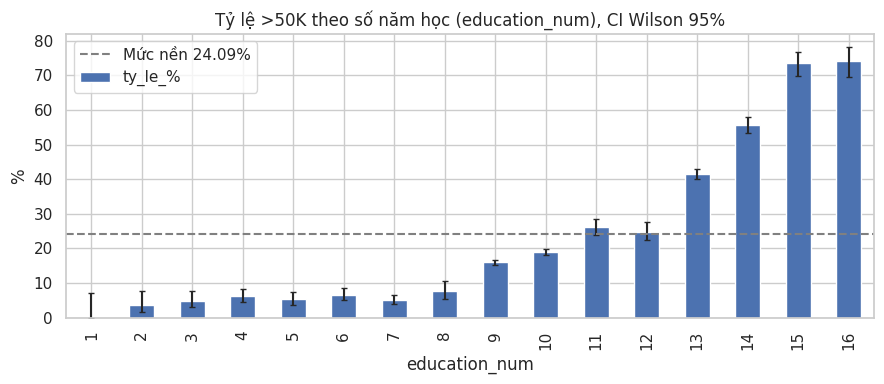

Spearman rho = 0.330, CI bootstrap 95% [0.320, 0.340], p < 0.001


education_num,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16
ty_le_%,0.0,3.6,4.8,6.2,5.3,6.6,5.1,7.6,16.0,19.0,26.1,24.8,41.5,55.7,73.4,74.1
ci_lo,0.0,1.7,3.0,4.6,3.6,5.2,4.0,5.5,15.3,18.1,23.9,22.3,40.2,53.3,69.7,69.7
ci_hi,7.1,7.7,7.7,8.3,7.5,8.4,6.5,10.5,16.7,20.0,28.5,27.5,42.8,58.0,76.9,78.1
n,50,166,332,645,514,933,1175,433,10494,7282,1382,1067,5353,1722,576,413
n_nho,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False


In [20]:
# H1 theo số năm học
t = rate_ci("education_num")
plot_rate_ci(t, kind="bar", title="Tỷ lệ >50K theo số năm học (education_num), CI Wilson 95%", figsize=(9, 4))
show("04_h1_education")

rho_h1, p_h1, rho_h1_lo, rho_h1_hi = spearman_boot(df["education_num"], df["income_bin"])
p_hyp["H1"] = p_h1
print(f"Spearman rho = {rho_h1:.3f}, CI bootstrap 95% [{rho_h1_lo:.3f}, {rho_h1_hi:.3f}], p {fmt_p(p_h1)}")
display(t[["ty_le_%", "ci_lo", "ci_hi", "n", "n_nho"]].round(1).T)


### H2. Tỷ lệ thu nhập cao tăng theo tuổi rồi giảm ở nhóm lớn tuổi

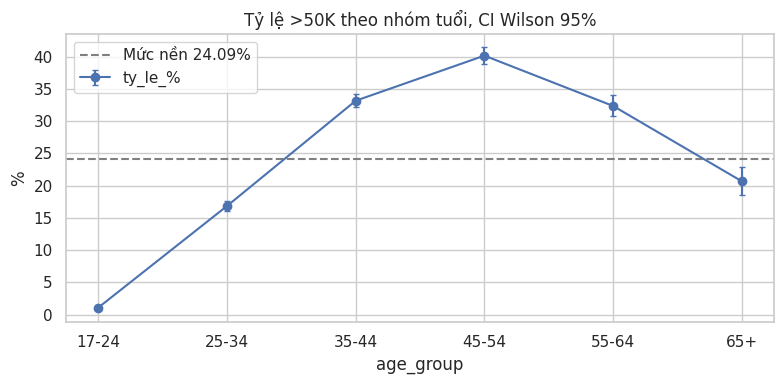

chi2 = 3168.5, p < 0.001, Cramér's V = 0.312


age_group,17-24,25-34,35-44,45-54,55-64,65+
ty_le_%,1.1,16.8,33.2,40.1,32.3,20.7
ci_lo,0.9,16.1,32.1,38.9,30.7,18.6
ci_hi,1.4,17.7,34.2,41.4,34.0,22.9
n,5562,8473,8146,5849,3172,1335
n_nho,False,False,False,False,False,False


Hội tụ: True
Hệ số age_c2 = -0.00346, CI 95% [-0.00363, -0.00329], p < 0.001
LR test bậc hai so với tuyến tính: chi2 = 2277.0, p < 0.001
Tuổi tại điểm cực đại: 50.4 | trong khoảng tuổi quan sát [17, 90]: True


In [21]:
# H2 theo nhóm tuổi
t = rate_ci("age_group")
plot_rate_ci(t, kind="line", title="Tỷ lệ >50K theo nhóm tuổi, CI Wilson 95%")
show("05_h2_age")

chi2, p, v = cramers_v(df["age_group"], df["income_bin"])
print(f"chi2 = {chi2:.1f}, p {fmt_p(p)}, Cramér's V = {v:.3f}")
display(t[["ty_le_%", "ci_lo", "ci_hi", "n", "n_nho"]].round(1).T)

# Chi-square không kiểm định được dạng đường cong có đỉnh nên dùng hồi quy logistic bậc hai.
# So mô hình tuyến tính với mô hình bậc hai bằng likelihood-ratio test.
m_lin = smf.logit("income_bin ~ age_c", df).fit(disp=0)
m_quad = smf.logit("income_bin ~ age_c + age_c2", df).fit(disp=0)
lr_h2 = 2 * (m_quad.llf - m_lin.llf)
p_h2 = stats.chi2.sf(lr_h2, 1)
p_hyp["H2"] = p_h2
b1, b2 = m_quad.params["age_c"], m_quad.params["age_c2"]
ci_b2 = m_quad.conf_int().loc["age_c2"].values
print("Hội tụ:", bool(m_quad.mle_retvals["converged"]))
print(f"Hệ số age_c2 = {b2:.5f}, CI 95% [{ci_b2[0]:.5f}, {ci_b2[1]:.5f}], p {fmt_p(m_quad.pvalues['age_c2'])}")
print(f"LR test bậc hai so với tuyến tính: chi2 = {lr_h2:.1f}, p {fmt_p(p_h2)}")
if b2 < 0:
    age_peak = df["age"].mean() - b1 / (2 * b2)
    print(f"Tuổi tại điểm cực đại: {age_peak:.1f} | trong khoảng tuổi quan sát "
          f"[{df['age'].min()}, {df['age'].max()}]: {df['age'].min() <= age_peak <= df['age'].max()}")
else:
    print("Hệ số age_c2 không âm, đường cong không có điểm cực đại dạng đỉnh")


### H3. Người làm nhiều giờ hơn có thu nhập cao hơn

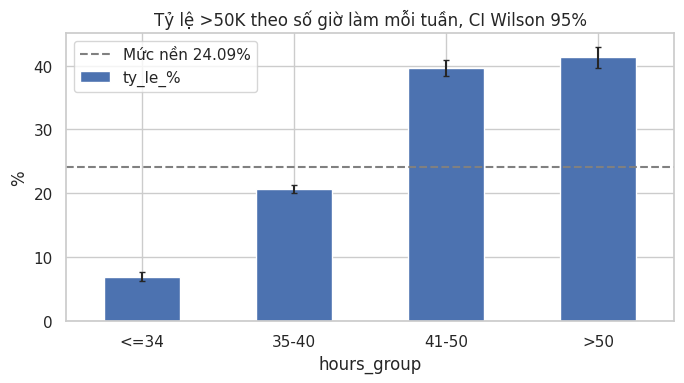

hours_group,<=34,35-40,41-50,>50
ty_le_%,6.9,20.7,39.6,41.3
ci_lo,6.3,20.1,38.4,39.7
ci_hi,7.6,21.3,40.9,42.9
n,5578,17383,5934,3642
n_nho,False,False,False,False


median: >50K = 40.0, <=50K = 40.0 | mean: >50K = 45.47, <=50K = 38.84
Mann-Whitney p < 0.001
Mann-Whitney U = 130,106,292
CLES = P(giờ làm >50K > giờ làm <=50K) + 0.5 P(bằng) = 0.672 | rank-biserial = 0.344
Spearman rho = 0.269, CI bootstrap 95% [0.259, 0.279], p < 0.001


In [22]:
# H3 theo số giờ làm
t = rate_ci("hours_group")
plot_rate_ci(t, kind="bar", title="Tỷ lệ >50K theo số giờ làm mỗi tuần, CI Wilson 95%", figsize=(7, 4))
plt.xticks(rotation=0)
show("06_h3_hours")
display(t[["ty_le_%", "ci_lo", "ci_hi", "n", "n_nho"]].round(1).T)

# Mann-Whitney vì hours_per_week dồn ở 40, không phân phối chuẩn
a = df.loc[df["income_bin"] == 1, "hours_per_week"]
b = df.loc[df["income_bin"] == 0, "hours_per_week"]
u, p, cles, rbc = cles_from_mwu(a, b)
p_hyp["H3"] = p
# Median của hai nhóm đều là 40 nên phải xem thêm trung bình
print(f"median: >50K = {a.median()}, <=50K = {b.median()} | mean: >50K = {a.mean():.2f}, <=50K = {b.mean():.2f}")
print(f"Mann-Whitney p {fmt_p(p)}")
print(f"Mann-Whitney U = {u:,.0f}")
print(f"CLES = P(giờ làm >50K > giờ làm <=50K) + 0.5 P(bằng) = {cles:.3f} | rank-biserial = {rbc:.3f}")
rho_h3, p_h3_sp, rho_h3_lo, rho_h3_hi = spearman_boot(df["hours_per_week"], df["income_bin"])
print(f"Spearman rho = {rho_h3:.3f}, CI bootstrap 95% [{rho_h3_lo:.3f}, {rho_h3_hi:.3f}], p {fmt_p(p_h3_sp)}")


### H4. Chênh lệch thu nhập theo giới tính còn lại gì sau khi tách theo hôn nhân và giờ làm

In [23]:
# H4 giới tính, số liệu thô
print(rate_by("sex"))
chi2, p, v = cramers_v(df["sex"], df["income_bin"])
print(f"Giới tính: Cramér's V = {v:.3f}, p {fmt_p(p)}")
p_sex_raw = rate_by("sex")["ty_le_%"]
print(f"Chênh lệch thô nam - nữ = {p_sex_raw['Male'] - p_sex_raw['Female']:.1f} điểm phần trăm, "
      f"Cohen's h = {cohen_h(p_sex_raw['Male'] / 100, p_sex_raw['Female'] / 100):.3f}")


        ty_le_%      n
sex                   
Female     11.0  10762
Male       30.6  21775
Giới tính: Cramér's V = 0.216, p < 0.001
Chênh lệch thô nam - nữ = 19.6 điểm phần trăm, Cohen's h = 0.496


Theo hôn nhân x giới tính:
                    mean   size
is_married sex                 
Khác       Female  0.047   9105
           Male    0.086   8462
Đã kết hôn Female  0.455   1657
           Male    0.446  13313

Theo giờ làm x giới tính:
sex          Female   Male
hours_group               
<=34          0.062  0.077
35-40         0.103  0.263
41-50         0.216  0.441
>50           0.204  0.451


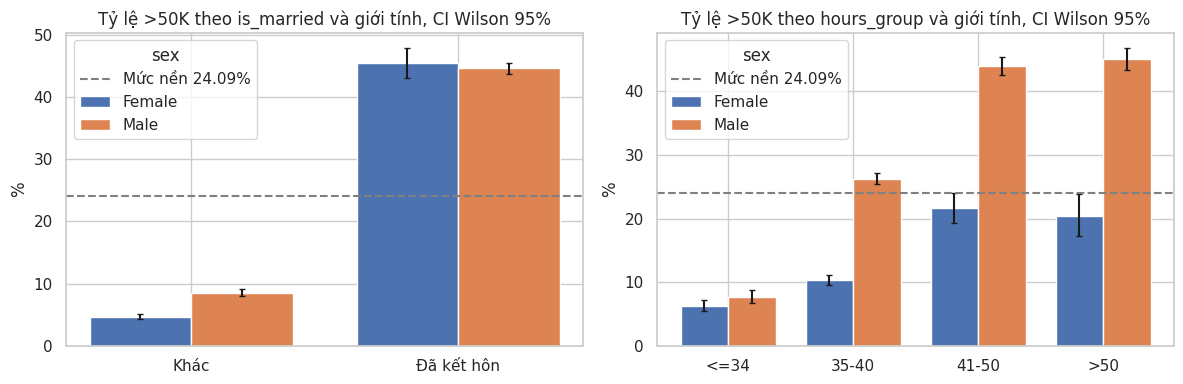

In [24]:
# H4 tách theo hôn nhân và giờ làm để xem chênh lệch thô có còn không
df["is_married"] = np.where(df["marital_status"] == "Married-civ-spouse", "Đã kết hôn", "Khác")
print("Theo hôn nhân x giới tính:")
print(df.groupby(["is_married", "sex"])["income_bin"].agg(["mean", "size"]).round(3))
print("\nTheo giờ làm x giới tính:")
print(df.groupby(["hours_group", "sex"], observed=True)["income_bin"].mean().unstack().round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, g in zip(axes, ["is_married", "hours_group"]):
    # Cột nhóm theo giới tính, error bar là CI Wilson 95% của từng ô (nhóm x giới tính)
    cell = df.groupby([g, "sex"], observed=True)["income_bin"].agg(k="sum", n="size")
    groups = list(cell.index.get_level_values(0).unique())
    w = 0.38
    for j, sx in enumerate(["Female", "Male"]):
        sub = cell.xs(sx, level=1).reindex(groups)
        lo, hi = proportion_confint(sub["k"], sub["n"], alpha=0.05, method="wilson")
        pr = sub["k"] / sub["n"] * 100
        ax.bar(np.arange(len(groups)) + (j - 0.5) * w, pr, w, label=sx,
               yerr=[pr - lo * 100, hi * 100 - pr], capsize=2)
    ax.set_xticks(np.arange(len(groups))); ax.set_xticklabels(groups)
    ax.axhline(BASE, ls="--", color="gray", label=f"Mức nền {BASE:.2f}%")
    ax.set_title(f"Tỷ lệ >50K theo {g} và giới tính, CI Wilson 95%")
    ax.set_ylabel("%"); ax.legend(title="sex")
show("07_h4_sex")


In [25]:
# H4: hồi quy logistic lồng nhau, Male là nhóm tham chiếu nên OR là của nữ so với nam.
# Gộp các mức có n < 50 của workclass và occupation vào "Unknown" cho M3 để tránh
# phân tách hoàn toàn (quasi-separation), không xóa dòng nào.
for c in ["workclass", "occupation"]:
    vc = df[c].value_counts()
    df[c + "_m3"] = df[c].where(df[c].map(vc) >= 50, "Unknown")

SEX = 'C(sex, Treatment(reference="Male"))'
M2_VARS = "age_c + age_c2 + education_num + hours_per_week + has_cap_gain + has_cap_loss"
f_h4 = {
    "M0": f"income_bin ~ {SEX}",
    "M1": f"income_bin ~ {SEX} + C(marital_status)",
    "M2": f"income_bin ~ {SEX} + C(marital_status) + {M2_VARS}",
    "M3": f"income_bin ~ {SEX} + C(marital_status) + {M2_VARS} + C(occupation_m3) + C(workclass_m3)",
}
SEX_TERM = f"{SEX}[T.Female]"

def fit_logit(formula, d):
    m = smf.logit(formula, d).fit(disp=0, maxiter=200)
    return m

def adj_diff(m, d):
    # Chênh lệch xác suất dự đoán trung bình: tất cả là nữ trừ tất cả là nam, giữ nguyên các biến khác
    dF, dM = d.copy(), d.copy()
    dF["sex"], dM["sex"] = "Female", "Male"
    return m.predict(dF).mean() - m.predict(dM).mean()

h4_models, h4_rows = {}, []
for name, f in f_h4.items():
    m = fit_logit(f, df)
    h4_models[name] = m
    ci = np.exp(m.conf_int().loc[SEX_TERM].values)
    h4_rows.append({"mo_hinh": name, "n_quan_sat": int(m.nobs), "OR_nu_vs_nam": np.exp(m.params[SEX_TERM]),
                    "CI95_lo": ci[0], "CI95_hi": ci[1], "p": fmt_p(m.pvalues[SEX_TERM]).replace("= ", ""),
                    "pseudoR2": m.prsquared, "hoi_tu": bool(m.mle_retvals["converged"]),
                    "|coef|_max": float(np.abs(m.params).max()),
                    "AME_nu_vs_nam_diem%": adj_diff(m, df) * 100})
h4_tbl = pd.DataFrame(h4_rows).set_index("mo_hinh")
display(h4_tbl.round(3))
p_hyp["H4"] = h4_models["M2"].pvalues[SEX_TERM]   # p của hệ số giới tính còn lại sau điều chỉnh ở M2
print("Cảnh báo: có hệ số rất lớn, có thể có phân tách" if (h4_tbl["|coef|_max"] > 10).any() else "Không thấy dấu hiệu phân tách (|coef| < 10)")

,n_quan_sat,OR_nu_vs_nam,CI95_lo,CI95_hi,p,pseudoR2,hoi_tu,|coef|_max,AME_nu_vs_nam_diem%
mo_hinh,,,,,,,,,
M0,32537,0.279,0.261,0.299,< 0.001,0.047,True,1.276,-19.630
M1,32537,0.728,0.672,0.789,< 0.001,0.198,True,1.970,-4.582
M2,32537,0.838,0.764,0.919,< 0.001,0.378,True,7.380,-1.921
M3,32537,0.823,0.746,0.909,< 0.001,0.401,True,6.266,-2.029


Không thấy dấu hiệu phân tách (|coef| < 10)


In [26]:
# H4: CI bootstrap 95% cho chênh lệch xác suất đã điều chỉnh (nữ - nam). Lấy mẫu lại theo dòng.
B_MODEL = 200
rng_h4 = np.random.default_rng(SEED)
boot_h4 = {k: [] for k in f_h4}
n_fail = {k: 0 for k in f_h4}
for _ in range(B_MODEL):
    db = df.iloc[rng_h4.integers(0, len(df), len(df))]
    for k, f in f_h4.items():
        try:
            boot_h4[k].append(adj_diff(fit_logit(f, db), db) * 100)
        except Exception:
            n_fail[k] += 1
ame_ci = pd.DataFrame({k: np.percentile(v, [2.5, 97.5]) for k, v in boot_h4.items()}, index=["lo", "hi"]).T
ame_ci["AME_diem%"] = h4_tbl["AME_nu_vs_nam_diem%"]
ame_ci["so_lan_loi"] = pd.Series(n_fail)
display(ame_ci.round(2))
print(f"Số lần bootstrap: {B_MODEL}")

,lo,hi,AME_diem%,so_lan_loi
M0,-20.57,-18.71,-19.63,0
M1,-5.92,-3.44,-4.58,0
M2,-2.97,-0.84,-1.92,0
M3,-3.20,-0.98,-2.03,0


Số lần bootstrap: 200


### H5. Tình trạng hôn nhân liên hệ mạnh với thu nhập

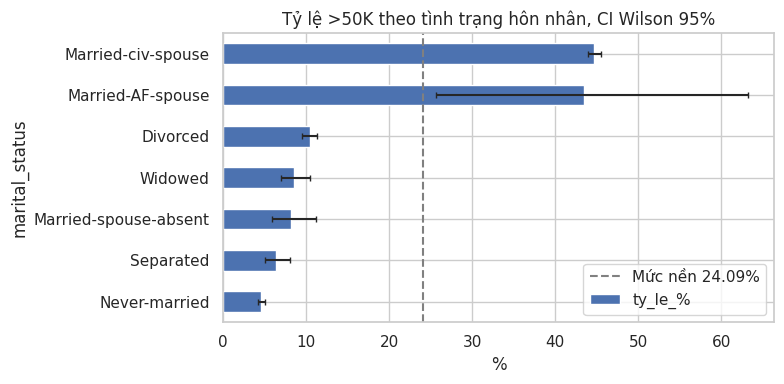

,ty_le_%,ci_lo,ci_hi,n,n_nho
marital_status,,,,,
Never-married,4.6,4.2,5.0,10667,False
Separated,6.4,5.1,8.1,1025,False
Married-spouse-absent,8.1,5.9,11.2,418,False
Widowed,8.6,7.0,10.5,993,False
Divorced,10.4,9.6,11.4,4441,False
Married-AF-spouse,43.5,25.6,63.2,23,True
Married-civ-spouse,44.7,43.9,45.5,14970,False


marital_status
Never-married            25.0
Married-AF-spouse        30.0
Separated                38.0
Married-spouse-absent    40.0
Married-civ-spouse       42.0
Divorced                 42.0
Widowed                  60.0
Name: age, dtype: float64
is_married   Khác  Đã kết hôn
age_group                    
17-24       0.005       0.070
25-34       0.050       0.336
35-44       0.107       0.503
45-54       0.144       0.560
55-64       0.113       0.445
65+         0.072       0.313


In [27]:
# H5 theo tình trạng hôn nhân
t = rate_ci("marital_status").sort_values("ty_le_%")
plot_rate_ci(t, title="Tỷ lệ >50K theo tình trạng hôn nhân, CI Wilson 95%", figsize=(8, 4), horizontal=True)
show("08_h5_marital")
display(t[["ty_le_%", "ci_lo", "ci_hi", "n", "n_nho"]].round(1))

# Hôn nhân đi cùng tuổi nên xem tuổi trung vị từng nhóm, rồi so sánh ngay trong từng nhóm tuổi
print(df.groupby("marital_status")["age"].median().sort_values())
print(df.groupby(["age_group", "is_married"], observed=True)["income_bin"].mean().unstack().round(3))


In [28]:
# H5: hồi quy logistic, Never-married là nhóm tham chiếu
MAR = 'C(marital_status, Treatment(reference="Never-married"))'
MARC = 'C(marital_status, Treatment(reference="Never-married"))[T.Married-civ-spouse]'
f_h5 = {
    "M1 hôn nhân": f"income_bin ~ {MAR}",
    "M2 + tuổi": f"income_bin ~ {MAR} + age_c + age_c2",
    "M3 + sex, học vấn, giờ, lãi vốn": f"income_bin ~ {MAR} + age_c + age_c2 + sex + education_num + hours_per_week + has_cap_gain + has_cap_loss",
}
# Mô hình tương ứng bỏ marital_status, dùng cho likelihood-ratio test đóng góp chung của biến này
f_h5_0 = {
    "M1 hôn nhân": "income_bin ~ 1",
    "M2 + tuổi": "income_bin ~ age_c + age_c2",
    "M3 + sex, học vấn, giờ, lãi vốn": "income_bin ~ age_c + age_c2 + sex + education_num + hours_per_week + has_cap_gain + has_cap_loss",
}
h5_rows, h5_models = [], {}
for name, f in f_h5.items():
    m, m0 = fit_logit(f, df), fit_logit(f_h5_0[name], df)
    h5_models[name] = m
    lr = 2 * (m.llf - m0.llf); df_lr = int(m.df_model - m0.df_model)
    ci = np.exp(m.conf_int().loc[MARC].values)
    h5_rows.append({"mo_hinh": name, "n_quan_sat": int(m.nobs), "OR_Married-civ-spouse_vs_Never-married": np.exp(m.params[MARC]),
                    "CI95_lo": ci[0], "CI95_hi": ci[1], "p_Wald": fmt_p(m.pvalues[MARC]).replace("= ", ""),
                    "LR_chi2": lr, "LR_df": df_lr, "p_LR": fmt_p(stats.chi2.sf(lr, df_lr)).replace("= ", ""),
                    "pseudoR2": m.prsquared, "hoi_tu": bool(m.mle_retvals["converged"])})
display(pd.DataFrame(h5_rows).set_index("mo_hinh").round(3))
last = list(f_h5)[-1]
p_hyp["H5"] = stats.chi2.sf(2 * (h5_models[last].llf - fit_logit(f_h5_0[last], df).llf),
                           int(h5_models[last].df_model - fit_logit(f_h5_0[last], df).df_model))

# Phân tích khám phá, không dùng làm kiểm định chính của H5: tương tác giới tính x đã kết hôn
f_a = f"income_bin ~ is_married + sex + {M2_VARS}"
f_b = f_a + " + is_married:sex"
ma, mb = fit_logit(f_a, df), fit_logit(f_b, df)
lr_int = 2 * (mb.llf - ma.llf)
print(f"[Khám phá] LR test tương tác sex x is_married: chi2 = {lr_int:.1f}, p {fmt_p(stats.chi2.sf(lr_int, 1))}")

,n_quan_sat,OR_Married-civ-spouse_vs_Never-married,CI95_lo,CI95_hi,p_Wald,LR_chi2,LR_df,p_LR,pseudoR2,hoi_tu
mo_hinh,,,,,,,,,,
M1 hôn nhân,32537,16.745,15.211,18.435,< 0.001,7057.619,6,< 0.001,0.196,True
M2 + tuổi,32537,7.848,7.085,8.693,< 0.001,4491.237,6,< 0.001,0.237,True
"M3 + sex, học vấn, giờ, lãi vốn",32537,9.755,8.692,10.948,< 0.001,3050.936,6,< 0.001,0.378,True


[Khám phá] LR test tương tác sex x is_married: chi2 = 164.3, p < 0.001


### Độ mạnh liên hệ giữa các biến và thu nhập

,V_chua_hieu_chinh,V_hieu_chinh,CI_duoi,CI_tren
bien,,,,
relationship,0.454,0.453,0.445,0.461
marital_status,0.447,0.447,0.439,0.456
education,0.369,0.368,0.358,0.379
occupation,0.352,0.351,0.342,0.362
sex,0.216,0.216,0.206,0.225
workclass,0.179,0.179,0.167,0.191
race,0.101,0.100,0.092,0.110
native_group,0.039,0.038,0.028,0.048


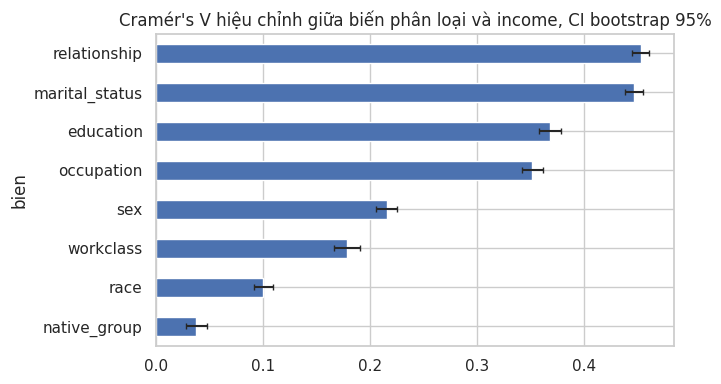

In [29]:
# So sánh độ mạnh liên hệ bằng Cramér's V hiệu chỉnh (Bergsma) kèm CI bootstrap 95%
cat_feats = ["workclass", "education", "marital_status", "occupation",
             "relationship", "race", "sex", "native_group"]
y_codes = codes(df["income_bin"])
v_rows = []
for c in cat_feats:
    xc = codes(df[c])
    lo_hi, _ = boot_ci(xc, y_codes, cramers_v_bc, B=1000)
    v_rows.append({"bien": c, "V_chua_hieu_chinh": cramers_v_raw(xc, y_codes),
                   "V_hieu_chinh": cramers_v_bc(xc, y_codes), "CI_duoi": lo_hi[0], "CI_tren": lo_hi[1]})
v_tbl = pd.DataFrame(v_rows).set_index("bien").sort_values("V_hieu_chinh", ascending=False)
display(v_tbl.round(3))

v_plot = v_tbl.sort_values("V_hieu_chinh")
xerr = [(v_plot["V_hieu_chinh"] - v_plot["CI_duoi"]).values, (v_plot["CI_tren"] - v_plot["V_hieu_chinh"]).values]
v_plot["V_hieu_chinh"].plot.barh(figsize=(7, 4), xerr=xerr, capsize=2,
                                 title="Cramér's V hiệu chỉnh giữa biến phân loại và income, CI bootstrap 95%")
show("09_cramers_v")


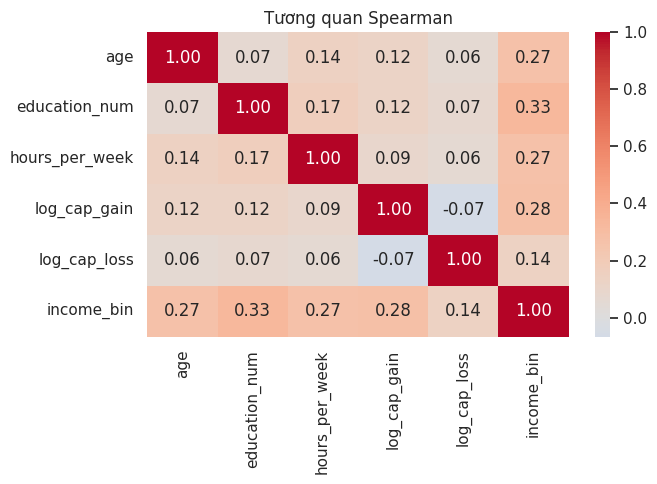

In [30]:
# Heatmap tương quan
# Spearman vì biến lệch và nhiều giá trị 0. Nó dựa trên thứ hạng nên dùng cột capital gốc
# hay cột log đều cho đúng cùng kết quả.
corr_cols = ["age", "education_num", "hours_per_week", "log_cap_gain", "log_cap_loss", "income_bin"]
plt.figure(figsize=(7, 5))
sns.heatmap(df[corr_cols].corr(method="spearman"), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Tương quan Spearman")
show("10_heatmap")

In [31]:
# Độ nhạy bằng trọng số fnlwgt: so tỷ lệ >50K chưa gia quyền và có gia quyền.
# Đây là phân tích mô tả, không phải suy luận theo thiết kế mẫu đầy đủ (thiếu strata và PSU).
def weighted_rate(col):
    w = df.assign(wy=df["fnlwgt"] * df["income_bin"]).groupby(col, observed=True)[["wy", "fnlwgt"]].sum()
    return w["wy"] / w["fnlwgt"] * 100

for col in ["age_group", "education_num", "sex", "is_married"]:
    cmp_tbl = pd.DataFrame({"chua_gia_quyen_%": df.groupby(col, observed=True)["income_bin"].mean() * 100,
                            "gia_quyen_%": weighted_rate(col)})
    cmp_tbl["lech_diem%"] = cmp_tbl["gia_quyen_%"] - cmp_tbl["chua_gia_quyen_%"]
    print(col)
    display(cmp_tbl.round(1))
print("Toàn mẫu: chưa gia quyền %.2f%%, gia quyền %.2f%%" % (
    df["income_bin"].mean() * 100, np.average(df["income_bin"], weights=df["fnlwgt"]) * 100))

age_group


,chua_gia_quyen_%,gia_quyen_%,lech_diem%
age_group,,,
17-24,1.1,1.2,0.1
25-34,16.8,16.9,0.0
35-44,33.2,33.4,0.3
45-54,40.1,40.7,0.6
55-64,32.3,33.2,0.8
65+,20.7,19.7,-1.0


education_num


,chua_gia_quyen_%,gia_quyen_%,lech_diem%
education_num,,,
1,0.0,0.0,0.0
2,3.6,3.5,-0.2
3,4.8,3.5,-1.3
4,6.2,5.8,-0.4
5,5.3,4.3,-0.9
6,6.6,6.7,0.0
7,5.1,4.4,-0.7
8,7.6,8.1,0.4
9,16.0,15.6,-0.4


sex


,chua_gia_quyen_%,gia_quyen_%,lech_diem%
sex,,,
Female,11.0,10.8,-0.1
Male,30.6,30.1,-0.5


is_married


,chua_gia_quyen_%,gia_quyen_%,lech_diem%
is_married,,,
Khác,6.5,6.4,-0.1
Đã kết hôn,44.7,45.0,0.3


Toàn mẫu: chưa gia quyền 24.09%, gia quyền 23.87%


In [32]:
# Hiệu chỉnh Holm cho năm p-value, coi H1 đến H5 là một họ kiểm định.
# H1 đến H3 là giả thuyết xác nhận, H4 và H5 mang tính khám phá nên Holm không đổi bản chất đó.
hyp_order = ["H1", "H2", "H3", "H4", "H5"]
pv = [p_hyp[h] for h in hyp_order]
reject, p_holm, _, _ = multipletests(pv, alpha=0.05, method="holm")
holm_tbl = pd.DataFrame({"p_goc": [fmt_p(p).replace("= ", "") for p in pv],
                         "p_Holm": [fmt_p(p).replace("= ", "") for p in p_holm],
                         "bac_bo_H0 (alpha=0.05)": reject}, index=hyp_order)
display(holm_tbl)

,p_goc,p_Holm,bac_bo_H0 (alpha=0.05)
H1,< 0.001,< 0.001,True
H2,< 0.001,< 0.001,True
H3,< 0.001,< 0.001,True
H4,< 0.001,< 0.001,True
H5,< 0.001,< 0.001,True


In [33]:
# Xuất dữ liệu đã làm sạch, không thay đổi df dùng trong phân tích
df.to_csv("adult_clean.csv", index=False)
print("Đã lưu adult_clean.csv:", df.shape)

Đã lưu adult_clean.csv: (32537, 28)


## Giai đoạn 4. Đánh giá tác động và khuyến nghị

Phần này được trình bày trong báo cáo, dựa trên kết quả của Giai đoạn 3.